In [6]:
hrdcore_model_path = r"C:\Users\rohit\Downloads\AI and Data Science\𝗙𝗮𝘀𝘁𝗔𝗣𝗜\Facial Emotion Recogination\models\resnet18_final.pth"

In [4]:
import torch
import torch.nn as nn
import torchvision.models as models

import torchvision.transforms as transforms
from PIL import Image

import matplotlib.pyplot as plt
import json
import os

from pathlib import Path

In [5]:
BASE_DIR = Path("..")

MODEL_PATH = BASE_DIR / "models" / "resnet18_final.pth"

CLASS_PATH = BASE_DIR / "models" / "class_names.json"

print("Model exists:", MODEL_PATH.exists())
print("Classes exist:", CLASS_PATH.exists())

Model exists: True
Classes exist: True


In [7]:
with open(CLASS_PATH, "r") as file:
    class_names = json.load(file)

print(class_names)

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [9]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [10]:
# Before loading the model, we need to understand what exactly is stored inside .pth file.

checkpoint = torch.load( MODEL_PATH,  map_location=device , weights_only=True)

print(type(checkpoint))

if isinstance(checkpoint, dict):
    print(checkpoint.keys())

<class 'dict'>
dict_keys(['model_name', 'model_state_dict', 'class_names', 'image_size', 'imagenet_mean', 'imagenet_std', 'val_accuracy', 'test_accuracy'])


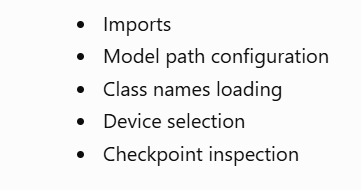

In [11]:
#recreate resnet and load it here 

# Extract information from checkpoint

class_names = checkpoint["class_names"]

IMAGE_SIZE = checkpoint["image_size"]

imagenet_mean = checkpoint["imagenet_mean"]

imagenet_std = checkpoint["imagenet_std"]


# Recreate ResNet18 architecture

model = models.resnet18(weights=None)

model.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(
        model.fc.in_features,
        len(class_names)
    )
)


# Load trained weights

model.load_state_dict(
    checkpoint["model_state_dict"]
)


# Move model to device

model = model.to(device)


# Set evaluation mode

model.eval()


print("ResNet18 loaded successfully!")
print("Classes:", class_names)
print("Image Size:", IMAGE_SIZE)
print("Test Accuracy:", checkpoint["test_accuracy"] * 100)

ResNet18 loaded successfully!
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Image Size: 128
Test Accuracy: 67.06603510727223


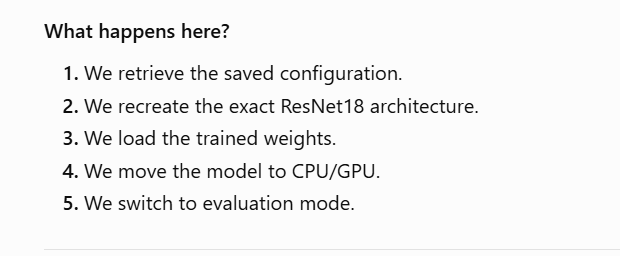

In [14]:
# Image preprocessing pipeline

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

print("Image preprocessing pipeline created successfully!")

Image preprocessing pipeline created successfully!


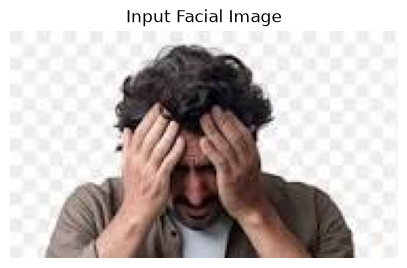

In [15]:
# Path to test image

IMAGE_PATH = r"C:\Users\rohit\Downloads\AI and Data Science\𝗙𝗮𝘀𝘁𝗔𝗣𝗜\Facial Emotion Recogination\notebook\sample.jpg"

# Load image and convert to RGB

image = Image.open(IMAGE_PATH).convert("RGB")

# Display image

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Input Facial Image")
plt.show()

In [16]:
# Apply preprocessing transformations

image_tensor = transform(image)

# Add batch dimension

image_tensor = image_tensor.unsqueeze(0)

# Display tensor shape

print("Tensor shape:", image_tensor.shape)

Tensor shape: torch.Size([1, 3, 128, 128])


In [17]:
# Move image tensor to the selected device

image_tensor = image_tensor.to(device)

# Perform inference

with torch.inference_mode():

    outputs = model(image_tensor)

    # Convert logits into probabilities

    probabilities = torch.softmax(outputs, dim=1)

    # Get predicted class and confidence

    confidence, predicted = torch.max(probabilities, dim=1)


# Extract prediction

predicted_class = class_names[predicted.item()]
confidence_score = confidence.item() * 100

print("Predicted Emotion:", predicted_class)
print(f"Confidence: {confidence_score:.2f}%")

Predicted Emotion: sad
Confidence: 54.06%


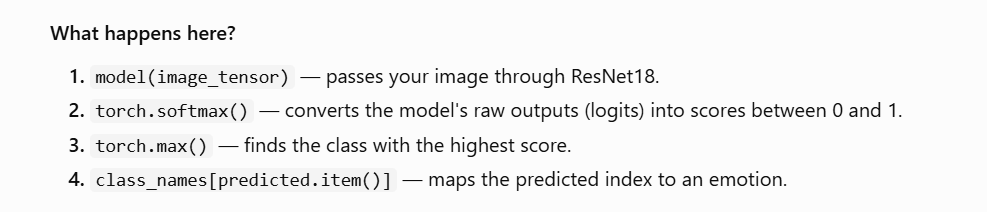

In [18]:
#done


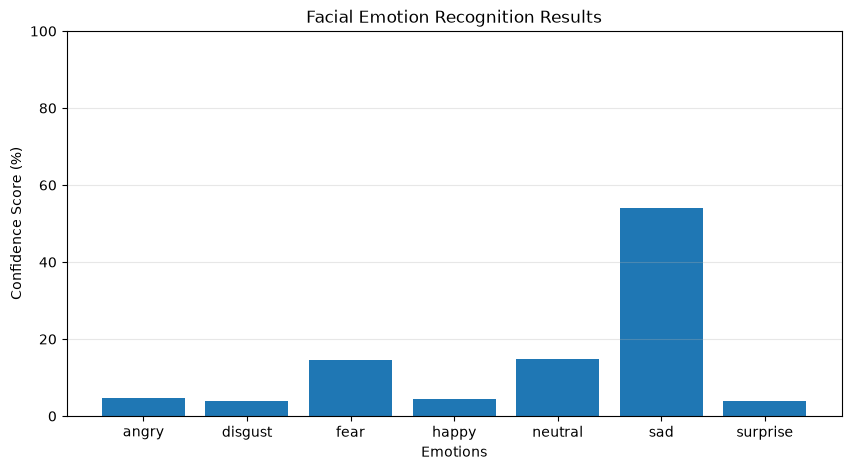

In [19]:
# Convert probabilities into a list

emotion_scores = probabilities[0].cpu().numpy() * 100

# Plot emotion scores

plt.figure(figsize=(10, 5))

plt.bar(class_names, emotion_scores)

plt.xlabel("Emotions")
plt.ylabel("Confidence Score (%)")
plt.title("Facial Emotion Recognition Results")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()


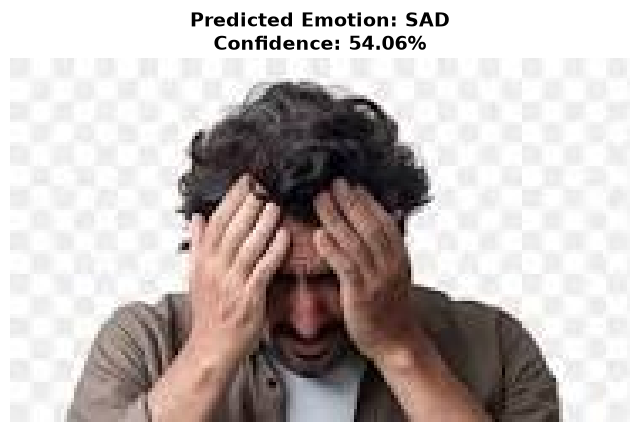

In [20]:
# Display final prediction

plt.figure(figsize=(8, 6))

plt.imshow(image)
plt.axis("off")

plt.title(
    f"Predicted Emotion: {predicted_class.upper()}\n"
    f"Confidence: {confidence_score:.2f}%",
    fontsize=14,
    fontweight="bold"
)

plt.show()